# Unit 2 Assignment 1: Linear Algebra & NumPy Practice
**Work Type:** Norah Alsuwailem, Raghad Alasmari, Fahad Al-Nahi, Rawan Alsubaie

---
## Task Scenario
Our group created a small dataset as a matrix: **student scores** (4 students × 3 subjects: Math, Physics, Chemistry).
Each **row** is a student and each **column** is a subject.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

data = np.array([
    [80, 90, 85],
    [70, 75, 78],
    [95, 88, 92],
    [60, 65, 70]
])

print("Dataset:")
print(data)
print("Shape:\n", data.shape)

Dataset:
[[80 90 85]
 [70 75 78]
 [95 88 92]
 [60 65 70]]
Shape:
 (4, 3)


# Part 1: NumPy & Math Foundations
## 1.1 & 1.2 Scalar, Vector, Matrix, Tensor (definitions + NumPy arrays)

| Concept | Definition | Dimensions (ndim) | Example |
|---|---|---|---|
| **Scalar** | A single number | 0 | one student's score: `85` |
| **Vector** | An ordered list of numbers (1D array) | 1 | scores of one student: `[80, 90, 85]` |
| **Matrix** | A 2D table of numbers (rows × columns) | 2 | the whole class scores table |
| **Tensor** | An array with 3 or more dimensions | 3+ | scores of several classes, or a color image (height × width × channels) |

In [ ]:
scalar = np.array(85)                       # one score
vector = np.array([80, 90, 85])             # one student's scores
matrix = data                               # all students
tensor = np.array([data, data + 5])         # 2 classes x 4 students x 3 subjects

print("Scalar:", scalar)
print("Vector:", vector)
print("Matrix:\n", matrix)
print("Tensor:\n", tensor)

Scalar: 85
Vector: [80 90 85]
Matrix:
 [[80 90 85]
 [70 75 78]
 [95 88 92]
 [60 65 70]]
Tensor:
 [[[ 80  90  85]
  [ 70  75  78]
  [ 95  88  92]
  [ 60  65  70]]

 [[ 85  95  90]
  [ 75  80  83]
  [100  93  97]
  [ 65  70  75]]]


## 1.3 Shape and dimensions

In [ ]:
for name, x in [("Scalar", scalar), ("Vector", vector), ("Matrix", matrix), ("Tensor", tensor)]:
    print(f"{name:7s} -> shape: {str(x.shape):12s} ndim: {x.ndim}  size: {x.size}")

Scalar  -> shape: ()           ndim: 0  size: 1
Vector  -> shape: (3,)         ndim: 1  size: 3
Matrix  -> shape: (4, 3)       ndim: 2  size: 12
Tensor  -> shape: (2, 4, 3)    ndim: 3  size: 24


## 1.4 Difference between `(n,)` and `(n,1)`

- **`(n,)`** is a **1D array** (a "flat" vector). It has only one axis, so it is neither a row nor a column.
- **`(n,1)`** is a **2D array** with `n` rows and **1 column**, a true **column vector**.

This matters in operations such as **broadcasting** and **matrix multiplication**. For example, a `(3,)` array plus a `(3,1)` array produces a `(3,3)` matrix, not a `(3,)` vector!

In [ ]:
a = np.array([1, 2, 3])        # shape (3,)
b = a.reshape(-1, 1)           # shape (3,1)

print("a shape:", a.shape, "| ndim:", a.ndim)
print("b shape:", b.shape, "| ndim:", b.ndim)
print("b =\n", b)

# Broadcasting difference:
print("\na + a  ->", a + a, " shape:", (a + a).shape)
print("a + b  ->\n", a + b, "\nshape:", (a + b).shape)

a shape: (3,) | ndim: 1
b shape: (3, 1) | ndim: 2
b =
 [[1]
 [2]
 [3]]

a + a  -> [2 4 6]  shape: (3,)
a + b  ->
 [[2 3 4]
 [3 4 5]
 [4 5 6]] 
shape: (3, 3)


## 1.5 Element-wise operations (addition, subtraction, multiplication, division)

In [ ]:
A = np.array([[1, 2, 3],
              [4, 5, 6]])
B = np.array([[10, 20, 30],
              [40, 50, 60]])

print("A + B =\n", A + B)
print("\nB - A =\n", B - A)
print("\nA * B (element-wise) =\n", A * B)
print("\nB / A =\n", B / A)

print("\n--- On our dataset ---")
print("data + 5 (bonus marks) =\n", data + 5)
print("\ndata / 100 (as fractions) =\n", data / 100)

A + B =
 [[11 22 33]
 [44 55 66]]

B - A =
 [[ 9 18 27]
 [36 45 54]]

A * B (element-wise) =
 [[ 10  40  90]
 [160 250 360]]

B / A =
 [[10. 10. 10.]
 [10. 10. 10.]]

--- On our dataset ---
data + 5 (bonus marks) =
 [[ 85  95  90]
 [ 75  80  83]
 [100  93  97]
 [ 65  70  75]]

data / 100 (as fractions) =
 [[0.8  0.9  0.85]
 [0.7  0.75 0.78]
 [0.95 0.88 0.92]
 [0.6  0.65 0.7 ]]


## 1.6 Aggregations (Sum, Mean, Min, Max, Standard deviation)
`axis=0` → computed down the **rows** (one result per **column/subject**).
`axis=1` → computed across the **columns** (one result per **row/student**).

In [ ]:
print("Sum  :", data.sum())
print("Mean :", data.mean())
print("Min  :", data.min())
print("Max  :", data.max())
print("Std  :", round(data.std(), 3))

print("\n--- Per subject (axis=0) ---")
print("Mean:", data.mean(axis=0))
print("Std :", data.std(axis=0).round(2))
print("Max :", data.max(axis=0))

print("\n--- Per student (axis=1) ---")
print("Sum :", data.sum(axis=1))
print("Mean:", data.mean(axis=1).round(2))
print("Min :", data.min(axis=1))

Sum  : 948
Mean : 79.0
Min  : 60
Max  : 95
Std  : 10.801

--- Per subject (axis=0) ---
Mean: [76.25 79.5  81.25]
Std : [12.93 10.16  8.17]
Max : [95 90 92]

--- Per student (axis=1) ---
Sum : [255 223 275 195]
Mean: [85.   74.33 91.67 65.  ]
Min : [80 70 88 60]


# Part 2: Vectors & Linear Algebra
## 2.1 & 2.2 Two vectors and their operations
Let **v = [3, 4]** and **w = [1, 2]**.

- **Vector addition:** add component by component: v + w = [v₁+w₁, v₂+w₂]
- **Scalar multiplication:** scales the length: c·v = [c·v₁, c·v₂]
- **Dot product:** v · w = v₁w₁ + v₂w₂ + ...
- **Norm (length):** ‖v‖ = √(v₁² + v₂² + ...)
- **Cosine similarity:** cos(θ) = (v · w) / (‖v‖ ‖w‖), ranges from −1 to 1

In [ ]:
v = np.array([3, 4])
w = np.array([1, 2])

print("v + w            =", v + w)
print("3 * v            =", 3 * v)
print("v . w (dot)      =", np.dot(v, w))
print("||v|| (norm)     =", np.linalg.norm(v))
print("||w|| (norm)     =", round(np.linalg.norm(w), 4))

cos_sim = np.dot(v, w) / (np.linalg.norm(v) * np.linalg.norm(w))
print("cosine similarity =", round(cos_sim, 4))
print("angle (degrees)   =", round(np.degrees(np.arccos(cos_sim)), 2))

v + w            = [4 6]
3 * v            = [ 9 12]
v . w (dot)      = 11
||v|| (norm)     = 5.0
||w|| (norm)     = 2.2361
cosine similarity = 0.9839
angle (degrees)   = 10.3


## 2.3 Row vector and column vector

In [ ]:
row_vec = np.array([[1, 2, 3]])        # shape (1,3)
col_vec = np.array([[1], [2], [3]])    # shape (3,1)

print("Row vector:", row_vec, "shape:", row_vec.shape)
print("Column vector:\n", col_vec, "\nshape:", col_vec.shape)

# Transpose converts one into the other
print("\nTranspose of row vector:\n", row_vec.T, "\nshape:", row_vec.T.shape)

# row (1x3) @ col (3x1) = 1x1  (this is the dot product)
print("\nrow @ col =", row_vec @ col_vec)
# col (3x1) @ row (1x3) = 3x3  (outer product)
print("\ncol @ row =\n", col_vec @ row_vec)

Row vector: [[1 2 3]] shape: (1, 3)
Column vector:
 [[1]
 [2]
 [3]] 
shape: (3, 1)

Transpose of row vector:
 [[1]
 [2]
 [3]] 
shape: (3, 1)

row @ col = [[14]]

col @ row =
 [[1 2 3]
 [2 4 6]
 [3 6 9]]


## 2.4 Meaning of the dot product
The dot product relates to the angle θ between vectors: **v · w = ‖v‖‖w‖cos(θ)**

| Dot product | Angle θ | Meaning |
|---|---|---|
| **Positive** | θ < 90° | vectors point in a **similar direction** |
| **Zero** | θ = 90° | vectors are **perpendicular (orthogonal)**, no similarity |
| **Negative** | θ > 90° | vectors point in **opposite directions** |

Positive: [1 2] . [3 4] =   11   angle =   10.3 deg
Zero    : [1 0] . [0 1] =    0   angle =   90.0 deg
Negative: [1 2] . [-3 -4] =  -11   angle =  169.7 deg


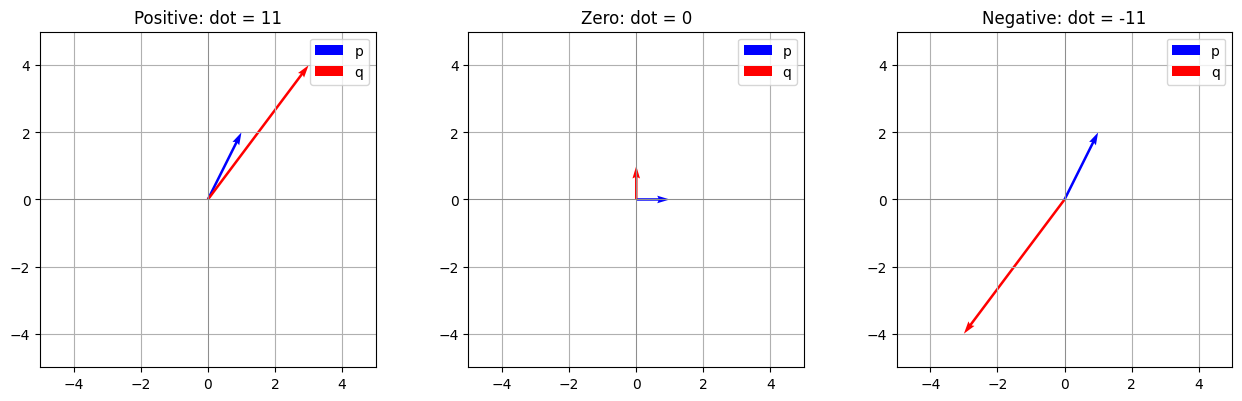

In [ ]:
cases = {
    "Positive": (np.array([1, 2]),  np.array([3, 4])),
    "Zero":     (np.array([1, 0]),  np.array([0, 1])),
    "Negative": (np.array([1, 2]),  np.array([-3, -4])),
}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (name, (p, q)) in zip(axes, cases.items()):
    d = np.dot(p, q)
    ang = np.degrees(np.arccos(d / (np.linalg.norm(p) * np.linalg.norm(q))))
    print(f"{name:8s}: {p} . {q} = {d:4d}   angle = {ang:6.1f} deg")
    ax.quiver(0, 0, *p, angles='xy', scale_units='xy', scale=1, color='blue', label='p')
    ax.quiver(0, 0, *q, angles='xy', scale_units='xy', scale=1, color='red', label='q')
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
    ax.axhline(0, color='gray', lw=0.5); ax.axvline(0, color='gray', lw=0.5)
    ax.set_aspect('equal'); ax.grid(True); ax.legend()
    ax.set_title(f"{name}: dot = {d}")
plt.tight_layout(); plt.show()

## 2.5 Linear independence and basis of R²
Two vectors in R² are **linearly independent** if neither is a multiple of the other, meaning
`c₁v₁ + c₂v₂ = 0` only when `c₁ = c₂ = 0`.

**Test:** put them as columns of a matrix M. They are independent if **det(M) ≠ 0** (equivalently **rank(M) = 2**).

If two independent vectors exist in R², they **span** the whole plane and therefore form a **basis for R²**.

In [ ]:
def check_independence(v1, v2):
    M = np.column_stack([v1, v2])
    det = np.linalg.det(M)
    rank = np.linalg.matrix_rank(M)
    independent = rank == 2
    print(f"v1 = {v1}, v2 = {v2}")
    print(f"  det  = {det:.3f}")
    print(f"  rank = {rank}")
    print(f"  Linearly independent? {independent}")
    print(f"  Basis for R^2?        {independent}\n")

# Case 1: independent -> basis
check_independence(np.array([1, 0]), np.array([1, 1]))

# Case 2: dependent (v2 = 2*v1) -> NOT a basis
check_independence(np.array([1, 2]), np.array([2, 4]))

v1 = [1 0], v2 = [1 1]
  det  = 1.000
  rank = 2
  Linearly independent? True
  Basis for R^2?        True

v1 = [1 2], v2 = [2 4]
  det  = 0.000
  rank = 1
  Linearly independent? False
  Basis for R^2?        False



In [ ]:
# Bonus: with a basis, any point can be reached. Express target = c1*v1 + c2*v2
v1, v2 = np.array([1, 0]), np.array([1, 1])
target = np.array([5, 3])
coeffs = np.linalg.solve(np.column_stack([v1, v2]), target)
print("Coefficients (c1, c2):", coeffs)
print("Check c1*v1 + c2*v2 =", coeffs[0]*v1 + coeffs[1]*v2)

Coefficients (c1, c2): [2. 3.]
Check c1*v1 + c2*v2 = [5. 3.]


## 2.6 Linear combination: `a * v + b * w`
A linear combination mixes vectors using scalar weights. Changing a and b lets us reach different points in the plane (if v, w are independent, we can reach every point).

2*v + (-1)*w = [5 6]


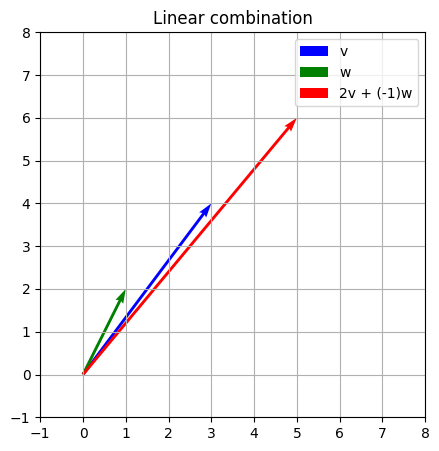

In [ ]:
a, b = 2, -1
lin_comb = a * v + b * w
print(f"{a}*v + ({b})*w = {lin_comb}")

fig, ax = plt.subplots(figsize=(5, 5))
for vec, c, lab in [(v, 'blue', 'v'), (w, 'green', 'w'), (lin_comb, 'red', f'{a}v + ({b})w')]:
    ax.quiver(0, 0, *vec, angles='xy', scale_units='xy', scale=1, color=c, label=lab)
ax.set_xlim(-1, 8); ax.set_ylim(-1, 8)
ax.set_aspect('equal'); ax.grid(True); ax.legend(); ax.set_title("Linear combination")
plt.show()

## 2.7 Linear transformations using a matrix
A matrix **M** transforms a vector **x** into **M·x**.

- **Scaling:** `[[sx,0],[0,sy]]` stretches the axes.
- **Rotation by θ:** `[[cosθ, -sinθ],[sinθ, cosθ]]`
- **Shear:** `[[1,k],[0,1]]` slides points horizontally in proportion to y.

We apply each to a unit square so the effect is visible.

In [ ]:
# Unit square (columns are points)
square = np.array([[0, 1, 1, 0, 0],
                   [0, 0, 1, 1, 0]])

# Scaling
S = np.array([[2, 0],
              [0, 1.5]])

# Rotation by 45 degrees
theta = np.radians(45)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])

# Shear
H = np.array([[1, 1],
              [0, 1]])

print("Scaling matrix:\n", S)
print("\nRotation matrix (45 deg):\n", R.round(3))
print("\nShear matrix:\n", H)

print("\nApplied to v =", v)
print("Scaling  S @ v =", S @ v)
print("Rotation R @ v =", (R @ v).round(3))
print("Shear    H @ v =", H @ v)
print("\nNorm before rotation:", np.linalg.norm(v), "| after:", round(np.linalg.norm(R @ v), 4), "(rotation preserves length)")

Scaling matrix:
 [[2.  0. ]
 [0.  1.5]]

Rotation matrix (45 deg):
 [[ 0.707 -0.707]
 [ 0.707  0.707]]

Shear matrix:
 [[1 1]
 [0 1]]

Applied to v = [3 4]
Scaling  S @ v = [6. 6.]
Rotation R @ v = [-0.707  4.95 ]
Shear    H @ v = [7 4]

Norm before rotation: 5.0 | after: 5.0 (rotation preserves length)


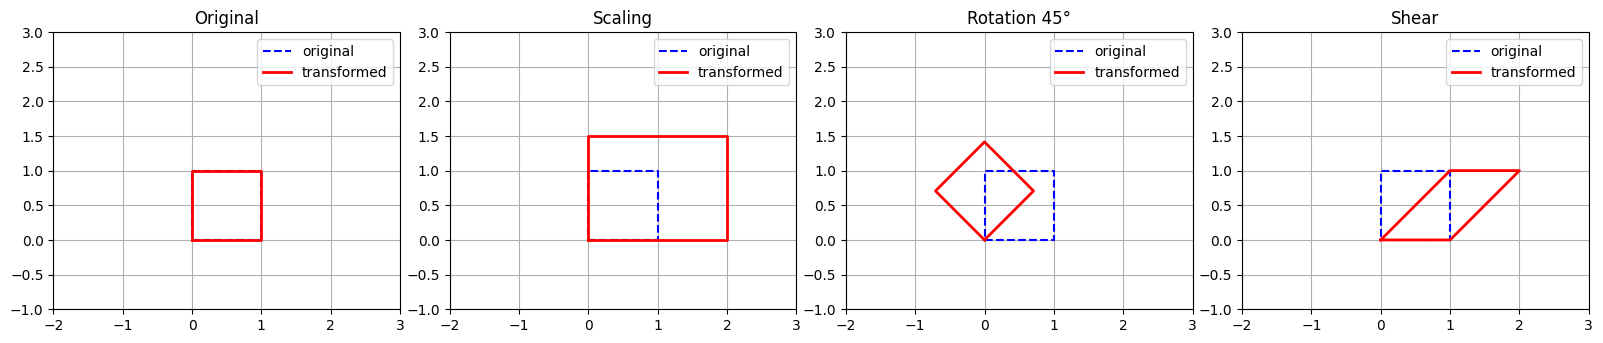

In [ ]:
transforms = [("Original", np.eye(2)), ("Scaling", S), ("Rotation 45°", R), ("Shear", H)]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, T) in zip(axes, transforms):
    out = T @ square
    ax.plot(square[0], square[1], 'b--', label='original')
    ax.plot(out[0], out[1], 'r-', lw=2, label='transformed')
    ax.set_xlim(-2, 3); ax.set_ylim(-1, 3)
    ax.set_aspect('equal'); ax.grid(True)
    ax.set_title(name); ax.legend()
plt.tight_layout(); plt.show()

# Final Question
## Why are vectors, matrices, and transformations important in Machine Learning?

1. **Data is represented as vectors and matrices.** Each sample is a feature vector (like one student's scores), and the whole dataset is a matrix X (samples × features). Images are tensors (height × width × channels).
2. **Models are built from matrix operations.** Linear regression is `y = Xw + b`. In a neural network every layer computes `activation(W·x + b)`, i.e. a linear transformation followed by a non-linearity.
3. **Learning = finding good matrices.** Training adjusts the weight matrices/vectors **W** to minimize error (gradients are vectors too).
4. **Dot product and cosine similarity measure similarity.** They power recommendation systems, semantic search, and word/text embeddings.
5. **Norms measure distance and size.** Used in KNN, clustering, and regularization (L1/L2) to prevent overfitting.
6. **Transformations change the representation of data.** PCA rotates/projects data to fewer dimensions, and neural nets transform data layer by layer into more useful representations.
7. **Linear independence and basis** tell us about redundant features and how many dimensions are really needed.
8. **Efficiency.** Vectorized NumPy operations are much faster than Python loops and map directly onto GPUs.

In [ ]:
# Mini demo: a "model" is just a dot product. Predict a final grade from the 3 subject scores.
weights = np.array([0.4, 0.3, 0.3])    # importance of each subject
predictions = data @ weights            # matrix-vector product
for i, p in enumerate(predictions, 1):
    print(f"Student {i}: predicted overall = {p:.2f}")

Student 1: predicted overall = 84.50
Student 2: predicted overall = 73.90
Student 3: predicted overall = 92.00
Student 4: predicted overall = 64.50
